# Conditioning of the 2-field and 3-field step matrices

The condition number $\mathrm{cond}_2(A) = \sigma_{\max}/\sigma_{\min}$ of the matrix that each model factorises once per run, on the annulus with the brain parameters (Morasca 2025), P2 elements. The studies are in this folder (`annulus_biot{2,3}_{h,dt}*.yaml`), the method in `docs/theory.md` §10 and `experiments/YAML_REFERENCE.md` §16.

- **raw**: $A$ as assembled, in the non-dimensional unknowns ($L_0$ = 1 cm, $T_0$ = 1 s, $P_0$ = 1500 Pa).
- **jacobi**: $|D|^{-1/2} A\,|D|^{-1/2}$ with $D = \mathrm{diag}(A)$. It removes the effect of the units of each block.
- **schur**: as jacobi, but each pressure unknown is scaled by the diagonal of an approximate Schur complement, $|a_{ii}| + \sum_{j \notin p} |a_{ij} a_{ji}|/|a_{jj}|$: what controls the pressure through its couplings. This is the scaling a block preconditioner uses (the `dt` studies were run before it existed and have raw and jacobi only).
- **$h_{\mathrm{eff}}$** $= (|\Omega|/N_{\mathrm{cells}})^{1/2}$: the gmsh annulus is unstructured, and its largest cell diameter hardly follows the refinement.

Run the notebook from this folder. Each study is computed once and saved to `results/<name>.npz`; later runs only load it (set `RERUN = True` to compute again; the largest takes about 15 minutes).

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FormatStrFormatter, NullLocator
from biotx import conditioning as cn

RERUN = False
NAMES = ["annulus_biot2_h", "annulus_biot3_h", "annulus_biot2_h_dt2.5ms", "annulus_biot3_h_dt2.5ms",
         "annulus_biot2_dt", "annulus_biot3_dt", "annulus_biot2_K", "annulus_biot3_K", "annulus_biot2_zeta"]
COLORS = {"biot2": "#2a78d6", "biot3": "#eb6834"}          # validated for colour-vision deficiency
MARKERS = {"biot2": "o", "biot3": "^"}
MODEL = {"biot2": "2F (d, p)", "biot3": "3F (d, w, p)"}
SCALING = {"raw": "raw", "jacobi": "Jacobi-scaled", "schur": "Schur-scaled"}
SC_COLORS = {"raw": "#b07d0a", "jacobi": "#7a4fc4", "schur": "#138a6a"}   # validated as well
SC_MARKERS = {"raw": "D", "jacobi": "s", "schur": "v"}


def get(name):
    path = Path("results") / f"{name}.npz"
    if RERUN or not path.exists():
        res = cn.run(cn.load(f"{name}.yaml"), verbose=True)
        print(res.table())
        res.save(path)
    return cn.load_result(path)


R = {n: get(n) for n in NAMES}


def model_of(r):
    return r["experiment"]["model"]


def x_of(r):
    # the swept quantity: h_eff in mm, dt in ms, other keys as given (K in m^2, zeta)
    key = str(r["key"])
    if key.startswith("geometry"):
        return r["h_eff"] * 1e3
    return r["values"].astype(float) * (1e3 if key == "time.dt" else 1.0)


def x_label(r):
    return {"time.dt": "dt [ms]", "material.K": "K [m^2]",
            "discretization.zeta": "zeta"}.get(str(r["key"]), "h eff [mm]")


def scalings(r):
    return [sc for sc in SCALING if f"{sc}_cond" in r]


def last_slope(x, y):
    return np.log(y[-1] / y[-2]) / np.log(x[-1] / x[-2])

## Tables

One table per study. `slope` is $\log(\mathrm{cond}_{i+1}/\mathrm{cond}_i)/\log(s_{i+1}/s_i)$ with $s = h_{\mathrm{eff}}$ or $\Delta t$. The `on` columns name the field that carries most of the singular vector of $\sigma_{\min}$ and of $\sigma_{\max}$ (its share of $|v|^2$).

In [2]:
def table(name):
    r = R[name]
    fields = [f for f in "dwp" if f"raw_share_min_{f}" in r]
    mesh = str(r["key"]).startswith("geometry")
    head = [x_label(r), "dofs"]
    for sc in scalings(r):
        head += [f"cond {sc}", "slope", "s_min on", "s_max on"]
    rows, x = [head], x_of(r)

    def on(sc, end, i):
        share = {f: r[f"{sc}_share_{end}_{f}"][i] for f in fields}
        f = max(share, key=share.get)
        return f"{f} {share[f]:.2f}"

    for i in range(len(x)):
        row = [f"{x[i]:.3g}", str(int(r["dofs"][i]))]
        for sc in scalings(r):
            c = r[f"{sc}_cond"]
            row += [f"{c[i]:.2e}", f"{np.log(c[i] / c[i - 1]) / np.log(x[i] / x[i - 1]):.2f}" if i else "",
                    on(sc, "min", i), on(sc, "max", i)]
        rows.append(row)
    w = [max(len(row[j]) for row in rows) for j in range(len(head))]
    dt = r["experiment"]["time"]["dt"] * 1e3
    print(f"{name}: {MODEL[model_of(r)]}" + (f", dt = {dt:g} ms" if mesh else ", h = 0.5 mm"))
    for row in rows:
        print("  " + "  ".join(c.rjust(wj) for c, wj in zip(row, w)))
    print()


for name in NAMES:
    table(name)

annulus_biot2_h: 2F (d, p), dt = 10 ms
  h eff [mm]   dofs  cond raw  slope  s_min on  s_max on  cond jacobi  slope  s_min on  s_max on  cond schur  slope  s_min on  s_max on
        1.66   1872  7.20e+04           p 1.00    d 1.00     1.09e+04           p 0.99    d 1.00    1.09e+04           p 0.99    d 1.00
        1.19   3636  1.35e+05  -1.90    p 1.00    d 1.00     2.15e+04  -2.06    p 1.00    d 1.00    2.15e+04  -2.06    p 1.00    d 1.00
       0.633  12852  4.56e+05  -1.93    p 1.00    d 1.00     7.89e+04  -2.06    p 0.99    d 1.00    7.89e+04  -2.06    p 0.99    d 1.00
       0.323  49248  1.73e+06  -1.98    p 1.00    d 1.00     3.14e+05  -2.06    p 0.99    d 1.00    3.14e+05  -2.06    p 0.99    d 1.00

annulus_biot3_h: 3F (d, w, p), dt = 10 ms
  h eff [mm]   dofs  cond raw  slope  s_min on  s_max on  cond jacobi  slope  s_min on  s_max on  cond schur  slope  s_min on  s_max on
        1.66   2808  2.80e+06           p 1.00    w 1.00     2.05e+04           d 1.00    p 0.54    5.

## Condition number against the mesh size

Solid: $\Delta t$ = 10 ms (the experiment). Dashed: $\Delta t$ = 2.5 ms. The legend gives the slope of the last refinement; the triangles show $h^{-2}$ (the SIPG prediction) and $h^{-3}$. Raw, Jacobi- and Schur-scaled from left to right.

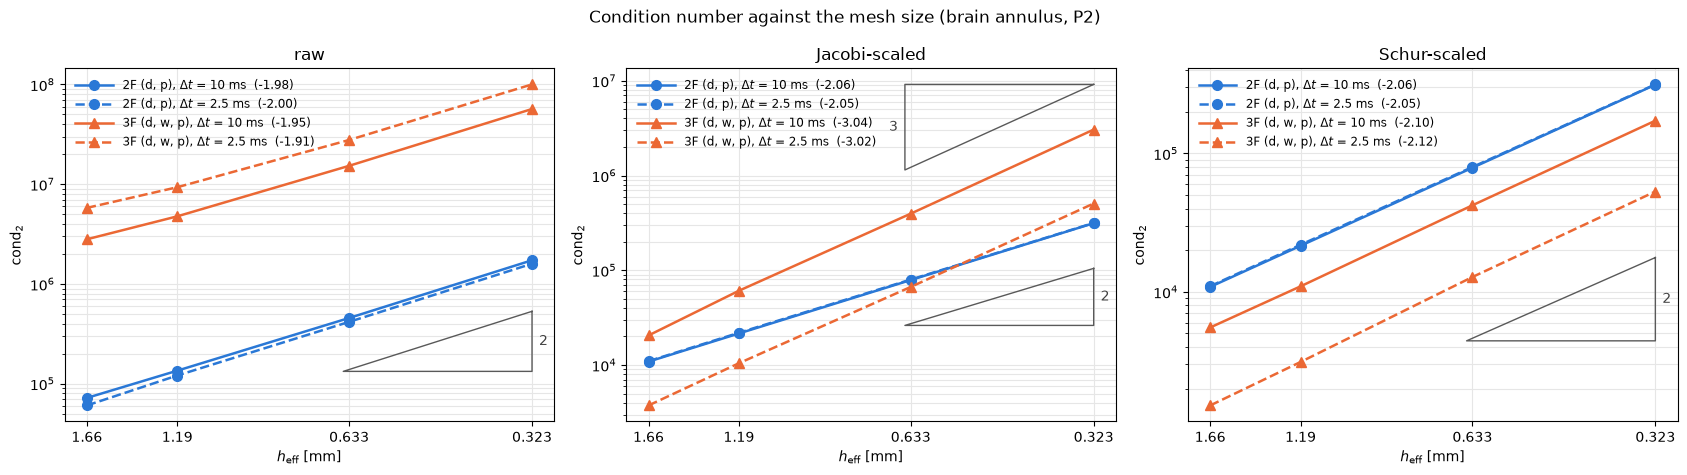

In [3]:
def triangle(ax, x0, y0, order, below=True):
    # slope triangle for cond ~ h^-order, between h = x0 (the finest) and 2 x0, a factor 3 away from y0
    x1 = 2 * x0
    if below:                                       # right angle under the hypotenuse
        top = y0 / 3
        ax.plot([x0, x0, x1, x0], [top, top / 2**order, top / 2**order, top], color="0.35", lw=1)
        ax.annotate(f"{order}", (x0, top / 2**(order / 2)), xytext=(5, 0), textcoords="offset points",
                    ha="left", va="center", color="0.25")
    else:                                           # right angle above it
        top = y0 * 3
        bot = top / 2**order
        ax.plot([x0, x1, x1, x0], [top, top, bot, top], color="0.35", lw=1)
        ax.annotate(f"{order}", (x1, top / 2**(order / 2)), xytext=(-5, 0), textcoords="offset points",
                    ha="right", va="center", color="0.25")


def style(ax, xlabel, ylabel, title, ticks, invert=True):
    if invert:
        ax.invert_xaxis()                           # refinement to the right
    ax.xaxis.set_major_locator(FixedLocator(ticks))  # label the computed values, not decades
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.3g"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(True, which="both", color="0.9")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend(frameon=False, fontsize=8.5, handlelength=3.2)


fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, sc in zip(axes, SCALING):
    finest = []
    for model in ("biot2", "biot3"):
        for suffix, ls, dt in (("", "-", 10), ("_dt2.5ms", "--", 2.5)):
            r = R[f"annulus_{model}_h{suffix}"]
            x, y = x_of(r), r[f"{sc}_cond"]
            ax.loglog(x, y, ls, marker=MARKERS[model], color=COLORS[model], lw=1.8, ms=7,
                      label=f"{MODEL[model]}, $\\Delta t$ = {dt:g} ms  ({last_slope(x, y):.2f})")
            finest.append(y[-1])
    x0 = x[-1]
    triangle(ax, x0, min(finest), 2, below=True)
    if sc == "jacobi":
        triangle(ax, x0, max(finest), 3, below=False)
    style(ax, "$h_{\\mathrm{eff}}$ [mm]", "cond$_2$", SCALING[sc], x)
fig.suptitle("Condition number against the mesh size (brain annulus, P2)")
fig.tight_layout()
plt.show()

## Condition number against the time step

On the mesh of the experiment ($h$ = 0.5 mm, $h_{\mathrm{eff}}$ = 0.32 mm). Smaller $\Delta t$ to the right.

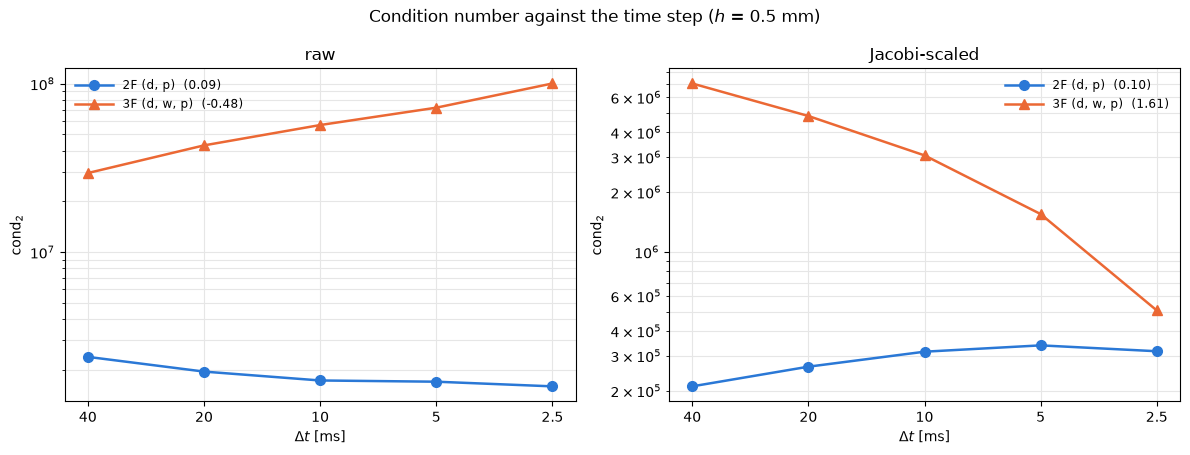

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, sc in zip(axes, ("raw", "jacobi")):
    for model in ("biot2", "biot3"):
        r = R[f"annulus_{model}_dt"]
        x, y = x_of(r), r[f"{sc}_cond"]
        ax.loglog(x, y, marker=MARKERS[model], color=COLORS[model], lw=1.8, ms=7,
                  label=f"{MODEL[model]}  ({last_slope(x, y):.2f})")
    style(ax, "$\\Delta t$ [ms]", "cond$_2$", SCALING[sc], x)
fig.suptitle("Condition number against the time step ($h$ = 0.5 mm)")
fig.tight_layout()
plt.show()

## Which end of the spectrum moves

$\mathrm{cond}_2 = \sigma_{\max}/\sigma_{\min}$, so each growth rate is split between the two ends. $\Delta t$ = 10 ms (solid) and 2.5 ms (dashed). $\sigma_{\min}$ is the same for both scalings (it lives on $d$ in 3F and on $p$ in 2F); only $\sigma_{\max}$ changes.

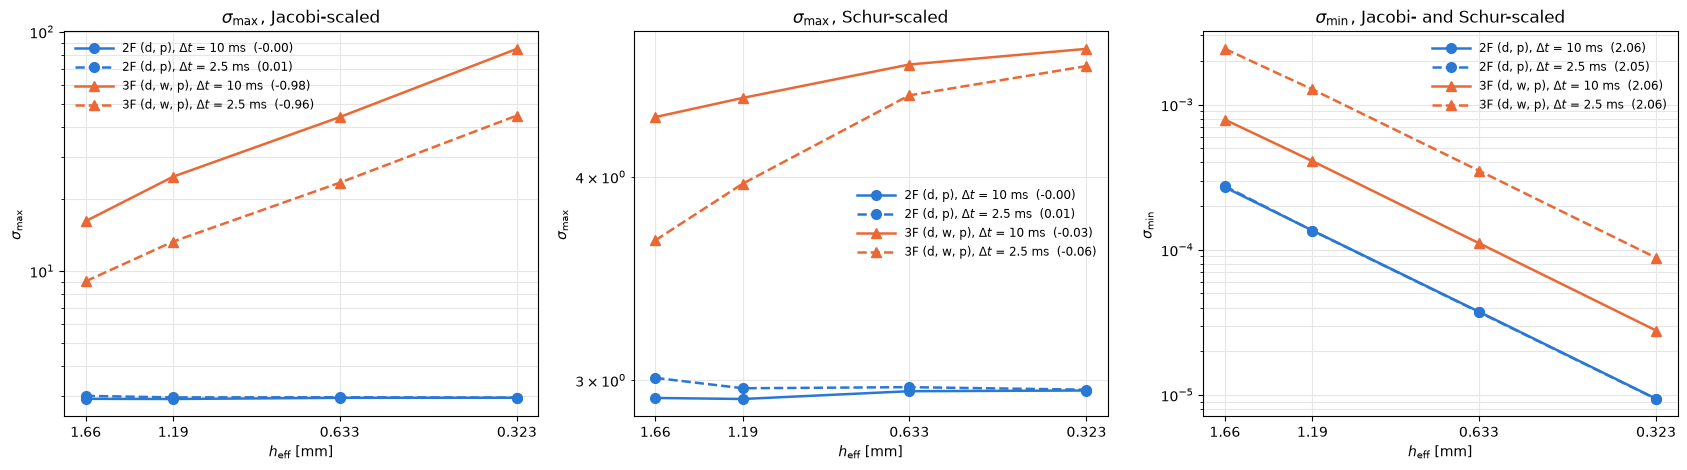

Jacobi-scaled, against dt (h = 0.5 mm): slope of the last step
  2F (d, p)     s_max -0.00   s_min -0.10
  3F (d, w, p)  s_max  0.47   s_min -1.14


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (sc, end) in zip(axes, (("jacobi", "smax"), ("schur", "smax"), ("schur", "smin"))):
    for model in ("biot2", "biot3"):
        for suffix, ls, dt in (("", "-", 10), ("_dt2.5ms", "--", 2.5)):
            r = R[f"annulus_{model}_h{suffix}"]
            x, y = x_of(r), r[f"{sc}_{end}"]
            ax.loglog(x, y, ls, marker=MARKERS[model], color=COLORS[model], lw=1.8, ms=7,
                      label=f"{MODEL[model]}, $\\Delta t$ = {dt:g} ms  ({last_slope(x, y):.2f})")
    name = "$\\sigma_{\\max}$" if end == "smax" else "$\\sigma_{\\min}$"
    title = f"{name}, {SCALING[sc]}" if end == "smax" else f"{name}, Jacobi- and Schur-scaled"
    style(ax, "$h_{\\mathrm{eff}}$ [mm]", name, title, x)
fig.tight_layout()
plt.show()

print("Jacobi-scaled, against dt (h = 0.5 mm): slope of the last step")
for model in ("biot2", "biot3"):
    r = R[f"annulus_{model}_dt"]
    x = x_of(r)
    print(f"  {MODEL[model]:13s} s_max {last_slope(x, r['jacobi_smax']):5.2f}   "
          f"s_min {last_slope(x, r['jacobi_smin']):5.2f}")

## Ratios: 3F against 2F, and raw against scaled

Left: cond(3F)/cond(2F) at the same mesh and time step, for each scaling (above 1: 3F is worse). Right: raw/Jacobi, the part of the condition number that is only a matter of units.

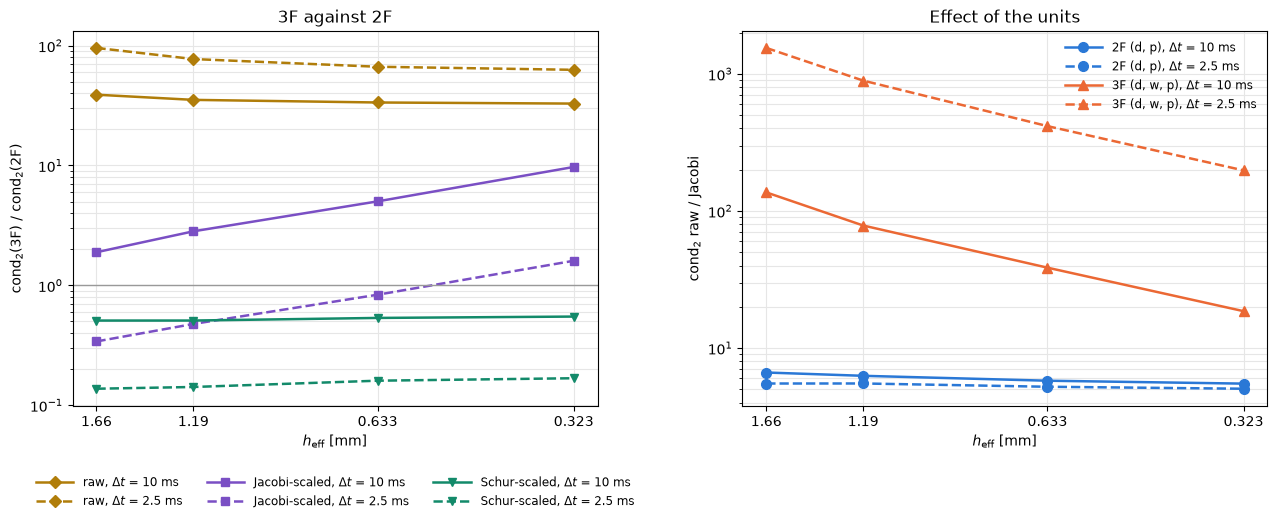

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
ax = axes[0]
for sc in SCALING:
    for suffix, ls, dt in (("", "-", 10), ("_dt2.5ms", "--", 2.5)):
        r2, r3 = R[f"annulus_biot2_h{suffix}"], R[f"annulus_biot3_h{suffix}"]
        x = x_of(r2)
        ax.loglog(x, r3[f"{sc}_cond"] / r2[f"{sc}_cond"], ls, marker=SC_MARKERS[sc], color=SC_COLORS[sc],
                  lw=1.8, ms=6, label=f"{SCALING[sc]}, $\\Delta t$ = {dt:g} ms")
ax.axhline(1, color="0.6", lw=1)
style(ax, "$h_{\\mathrm{eff}}$ [mm]", "cond$_2$(3F) / cond$_2$(2F)", "3F against 2F", x)
ax.legend(frameon=False, fontsize=8.5, handlelength=3.2, ncol=3, loc="upper center",
          bbox_to_anchor=(0.5, -0.16))                    # below: the lines fill the panel
ax = axes[1]
for model in ("biot2", "biot3"):
    for suffix, ls, dt in (("", "-", 10), ("_dt2.5ms", "--", 2.5)):
        r = R[f"annulus_{model}_h{suffix}"]
        ax.loglog(x_of(r), r["raw_cond"] / r["jacobi_cond"], ls, marker=MARKERS[model], color=COLORS[model],
                  lw=1.8, ms=7, label=f"{MODEL[model]}, $\\Delta t$ = {dt:g} ms")
style(ax, "$h_{\\mathrm{eff}}$ [mm]", "cond$_2$ raw / Jacobi", "Effect of the units", x_of(r))
fig.tight_layout()
plt.show()

## Permeability $K$

On the mesh of the experiment ($h$ = 0.5 mm, $\Delta t$ = 10 ms), two decades on each side of the brain value $1.57\cdot10^{-11}$ m² (marked). The analysis of the Jacobi-scaled 3-field matrix predicts $\mathrm{cond}_2 \propto \sqrt{K}$; the Schur scaling should remove that dependence.

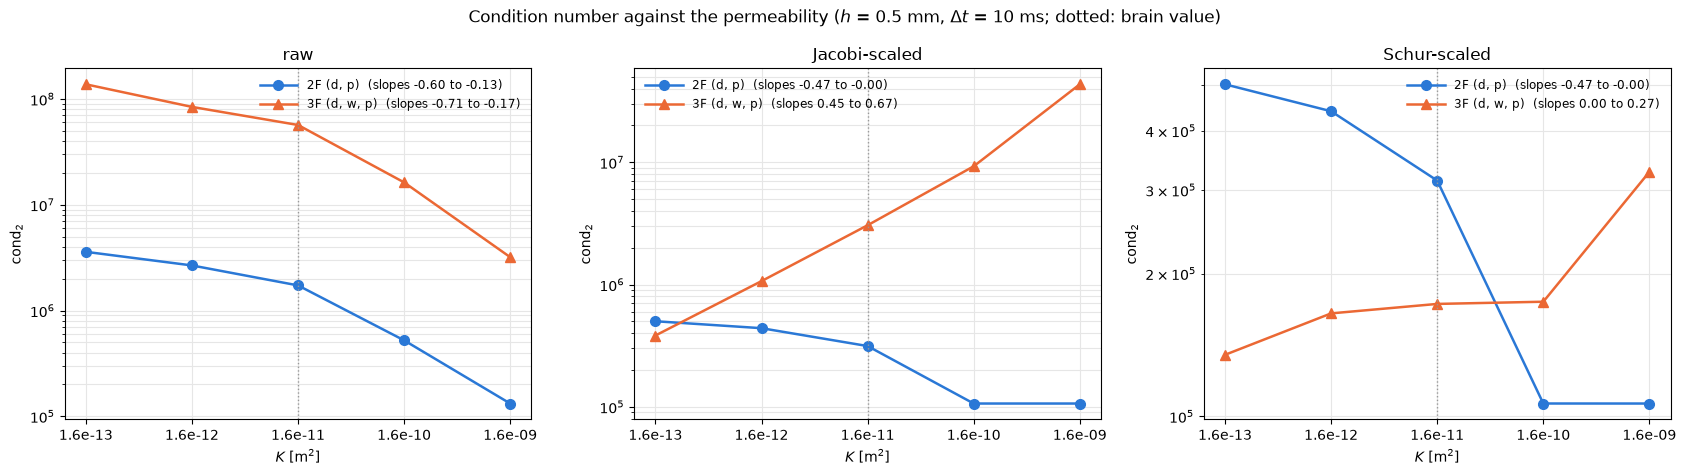

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, sc in zip(axes, SCALING):
    for model in ("biot2", "biot3"):
        r = R[f"annulus_{model}_K"]
        x, y = x_of(r), r[f"{sc}_cond"]
        sl = np.log(y[1:] / y[:-1]) / np.log(x[1:] / x[:-1])
        ax.loglog(x, y, marker=MARKERS[model], color=COLORS[model], lw=1.8, ms=7,
                  label=f"{MODEL[model]}  (slopes {sl.min():.2f} to {sl.max():.2f})")
    ax.axvline(1.57e-11, color="0.6", lw=1, ls=":")
    style(ax, "$K$ [m$^2$]", "cond$_2$", SCALING[sc], x, invert=False)
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.2g"))
fig.suptitle("Condition number against the permeability ($h$ = 0.5 mm, $\\Delta t$ = 10 ms; dotted: brain value)")
fig.tight_layout()
plt.show()

## Darcy penalty $\zeta$ (2-field)

The 2-field pressure jumps are penalised by $\zeta\,\tilde\kappa\,k^2/h_F$ with $\tilde\kappa = \max(\kappa^*, 1) = 1$ here, about $1.5\cdot10^4$ times the consistent $\zeta\,\kappa^* k^2/h_F$. Default $\zeta$ = 10 (marked). Same mesh and time step.

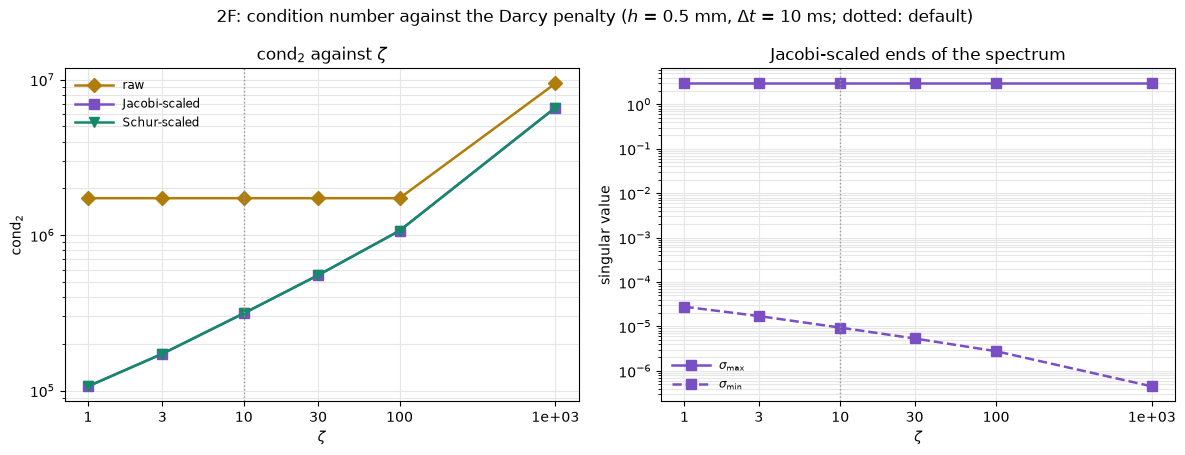

In [8]:
r = R["annulus_biot2_zeta"]
x = x_of(r)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
for sc in SCALING:
    ax.loglog(x, r[f"{sc}_cond"], marker=SC_MARKERS[sc], color=SC_COLORS[sc], lw=1.8, ms=7, label=SCALING[sc])
ax.axvline(10, color="0.6", lw=1, ls=":")
style(ax, "$\\zeta$", "cond$_2$", "cond$_2$ against $\\zeta$", x, invert=False)
ax = axes[1]
for end, ls in (("smax", "-"), ("smin", "--")):
    ax.loglog(x, r[f"jacobi_{end}"], ls, marker=SC_MARKERS["jacobi"], color=SC_COLORS["jacobi"], lw=1.8, ms=7,
              label="$\\sigma_{\\max}$" if end == "smax" else "$\\sigma_{\\min}$")
ax.axvline(10, color="0.6", lw=1, ls=":")
style(ax, "$\\zeta$", "singular value", "Jacobi-scaled ends of the spectrum", x, invert=False)
fig.suptitle("2F: condition number against the Darcy penalty ($h$ = 0.5 mm, $\\Delta t$ = 10 ms; dotted: default)")
fig.tight_layout()
plt.show()

## Reading the results

**Size.** The worst value is $10^8$ (3F raw, $\Delta t$ = 2.5 ms, $h$ = 0.5 mm): about 8 of the 16 digits of a direct solve remain. Conditioning is not an accuracy problem for MUMPS in 2D. For the mass-conservation checks (item 1), $\mathrm{cond}_2 \times 10^{-16}$ is the round-off floor below which an imbalance cannot be measured.

**Two-field.** $\mathrm{cond}_2 \sim h^{-2}$, raw and scaled, as SIPG predicts, and nearly independent of $\Delta t$ (less than a factor 1.5 over a factor 16 in $\Delta t$). $\sigma_{\max}$ is fixed and lives on $d$. $\sigma_{\min} \sim h^2$ lives on $p$, the weakly controlled field at low storage and permeability. Jacobi scaling gains a constant factor of about 5.

**Three-field, raw.** 30–100 times worse than 2F (33–39 at $\Delta t$ = 10 ms, 63–96 at 2.5 ms), also $\sim h^{-2}$, and growing as $\Delta t$ decreases. $\sigma_{\max}$ lives on $w$, the drag block $(1/\kappa)\,\gamma/(\beta\Delta t) \approx 3\cdot10^6$ times a mass matrix. $\sigma_{\min}$ lives on $p$.

**Three-field, Jacobi-scaled: $h^{-3}$.** The rate is the same at both time steps, so it is not a regime effect of the $h/\Delta t$ balance; smaller $\Delta t$ only lowers the curve. The split shows where it comes from: $\sigma_{\min} \sim h^2$ on $d$, as in 2F, but $\sigma_{\max} \sim h^{-1}\,\Delta t^{1/2}$, shared by $w$ and $p$ (2F: constant). That is the $w$–$p$ coupling $b_W$ after diagonal scaling. The $w$ diagonal is the drag mass, $\propto h^2/(\kappa\Delta t)$, and the $p$ diagonal is the storage mass, $\propto c_0 h^2$. A coupling entry $\propto h$ then becomes $\propto h^{-1}\sqrt{\kappa\Delta t/c_0}$, which matches both measured slopes. Jacobi scaling under-scales the pressure, which is controlled by the Schur complement $c_0 + \kappa\Delta t\,(-\Delta)$, not by $c_0$ alone.

**Three-field, Schur-scaled: $h^{-2}$.** Scaling the pressure by the diagonal of its approximate Schur complement bounds the scaled coupling by 1. $\sigma_{\max}$ stays near 4.7 at every mesh, and the slope returns to $-2.1$ at both time steps. The $h^{-3}$ was a property of the scaling, not of the formulation.

**Two-field, Schur-scaled.** Identical to Jacobi (to 3 digits), as expected: its pressure diagonal already contains the Darcy jump penalty, so the coupling adds almost nothing.

**3F against 2F.** Raw: 30–100 times worse, because of the units of its blocks. Jacobi: worse by a factor that grows like $1/h$. **Schur: 3F is better conditioned than 2F**, 0.55 times at $\Delta t$ = 10 ms and 0.17 times at 2.5 ms on the experiment's mesh, with the same $h^{-2}$ growth. Once each formulation is scaled according to its structure, the 3-field matrix is not the harder one.

**Permeability.** The predictions hold. Jacobi-scaled 3F has $\sigma_{\max} \propto K^{0.46}$, close to the predicted $\sqrt{K}$, so its cond falls from $4\cdot10^7$ to $4\cdot10^5$ as $K$ decreases. Schur-scaled 3F stays between $1.3\cdot10^5$ and $3.3\cdot10^5$ over four decades: robust in $K$. 2F worsens mildly as $K$ decreases (by about 5, levelling off below the brain value), because the penalty $\max(\kappa^*, 1)$ keeps holding the pressure. With Schur scaling 3F is better than 2F for $K \le 1.57\cdot10^{-11}$ m² (0.27 times at $1.57\cdot10^{-13}$) and up to 3 times worse at $1.57\cdot10^{-9}$, where the drag no longer dominates and $\sigma_{\min}$ moves to $w$. Raw 3F grows as $K$ decreases (drag $\propto 1/K$), up to $1.4\cdot10^8$.

**Darcy penalty (2F).** $\sigma_{\max}$ (on $d$) does not depend on $\zeta$ up to 100; $\sigma_{\min}$ (on $p$) falls like $\zeta^{-1/2}$, so cond grows like $\sqrt\zeta$. At $\zeta$ = 1000 the penalty also takes over $\sigma_{\max}$ and the raw cond jumps to $9\cdot10^6$. At $\zeta$ = 1, $\sigma_{\min}$ moves to $d$. The default $\zeta$ = 10 costs a factor of about 3 against $\zeta$ = 1. Conditioning says nothing about stability or accuracy: whether a smaller penalty, or the consistent $\tilde\kappa = \kappa^*$ (equivalent to $\zeta \approx 7\cdot10^{-4}$ here), is accurate and stable is an accuracy question, to settle with the flux checks of item 1.

**For later.**
- *Direct solver (now):* both formulations are fine. The raw numbers set the round-off floor of the mass-conservation checks.
- *Iterative solvers (3D, cluster):* 2F works with simple diagonal (Jacobi) preconditioning of its blocks. 3F needs a block preconditioner whose pressure block approximates the Schur complement $c_0 M + \kappa\Delta t\,(-\Delta_h)$. With it, 3F should do at least as well as 2F. That is more implementation work, but standard for Biot and Darcy problems.
- *Still open:* a coarse 3D check; the effect of the Darcy penalty on the accuracy of the 2F flux (item 1); a `material.c0` sweep if $c_0$ is to be varied.